In [1]:
from search_utils.utils import define_env
from search_utils.SearchAlgorithms import BFS, DFS, DFS_poda, BFS_poda, LowestSearch_Poda
from queue import PriorityQueue
from adabyron_environment.AdaByronDEMO_v2 import AdaByronDEMO
from adabyron_environment.agents.airConditioning_v2 import Airconditioning
from adabyron_environment.agents.storageBattery_v2 import StorageBattery
import itertools
from itertools import permutations
from datetime import date
import matplotlib.pyplot as plt
import random
import pandas as pd
import json
import paho.mqtt.client as mqtt
import paho.mqtt.subscribe as subscribe
# import copy

In [2]:
mercadoDiario   = pd.read_csv('test_data/mercadoDiario.csv', sep=';')
mercadoDiario['value'] = mercadoDiario['value']
mercadoDiario   = list(mercadoDiario['value'])

In [3]:
dict = {
    'ca_certs': "certs/ca.crt",
    'certfile': "certs/client.crt",
    'keyfile': "certs/client 1.key"
}

msg = subscribe.simple("flexener/data/adabyron", hostname="<MQTT_BROKER_IP>", port=8883, auth={'username':"<MQTT_USER>", 'password':"<MQTT_PASSWORD>"}, tls=dict)
print("%s %s" % (msg.topic, msg.payload))

data_dict = json.loads(msg.payload)

flexener/data/adabyron b'{"TimeStamp":"2024-06-04T10:22:35.6237552Z","Facility":"adabyron","Data":[{"Name":"ConsumoVrvZonaANorte","Value":5750.0},{"Name":"ConsumoTotal","Value":1467700.0},{"Name":"AdaByronBatteryPower","Value":0.948829},{"Name":"AdaByronBatterySoC","Value":52.936605},{"Name":"AdaByronBatteryTemperature","Value":20.0},{"Name":"ConsumoVrvZonaASur","Value":6050.0},{"Name":"ConsumoVrvZonaBNorte","Value":1500.0},{"Name":"ConsumoVrvZonaBSur","Value":3800.0},{"Name":"ConsumoClimatizadoraA","Value":0.0},{"Name":"ConsumoClimatizadoraB","Value":100.0},{"Name":"ConsumoBombaCalor","Value":2100.0},{"Name":"uma_loxone_speed_fans_mod_a","Value":10.0},{"Name":"uma_loxone_return_temp_b","Value":29.5},{"Name":"uma_loxone_return_temp_a","Value":24.125},{"Name":"uma_loxone_setpoint_mod_b","Value":18.0},{"Name":"uma_loxone_speed_fans_mod_b","Value":7.0},{"Name":"uma_loxone_setpoint_mod_a","Value":18.0},{"Name":"uma_loxone_weather_1:solarRadiation","Value":3.0},{"Name":"uma_loxone_weather_1

In [4]:
timestamp = data_dict["TimeStamp"]
consumo_total = 0
battery_power = 0
battery_soc   = 0
outside_temp  = 0
building_temp_a = 0
building_temp_b = 0

for data in data_dict["Data"]:
    if data["Name"] == "ConsumoTotal":
        consumo_total = data["Value"]
    if data["Name"] == "AdaByronBatteryPower":
        battery_power = data["Value"]
    if data["Name"] == "AdaByronBatterySoC":
        battery_soc = data["Value"]
    if data["Name"] == "uma_loxone_weather_1:temperature":
        outside_temp = data["Value"]
    if data["Name"] == "uma_loxone_return_temp_a":
        building_temp_a = data["Value"]
    if data["Name"] == "uma_loxone_return_temp_b":
        building_temp_b = data["Value"]



In [5]:
data_dict

{'TimeStamp': '2024-06-04T10:22:35.6237552Z',
 'Facility': 'adabyron',
 'Data': [{'Name': 'ConsumoVrvZonaANorte', 'Value': 5750.0},
  {'Name': 'ConsumoTotal', 'Value': 1467700.0},
  {'Name': 'AdaByronBatteryPower', 'Value': 0.948829},
  {'Name': 'AdaByronBatterySoC', 'Value': 52.936605},
  {'Name': 'AdaByronBatteryTemperature', 'Value': 20.0},
  {'Name': 'ConsumoVrvZonaASur', 'Value': 6050.0},
  {'Name': 'ConsumoVrvZonaBNorte', 'Value': 1500.0},
  {'Name': 'ConsumoVrvZonaBSur', 'Value': 3800.0},
  {'Name': 'ConsumoClimatizadoraA', 'Value': 0.0},
  {'Name': 'ConsumoClimatizadoraB', 'Value': 100.0},
  {'Name': 'ConsumoBombaCalor', 'Value': 2100.0},
  {'Name': 'uma_loxone_speed_fans_mod_a', 'Value': 10.0},
  {'Name': 'uma_loxone_return_temp_b', 'Value': 29.5},
  {'Name': 'uma_loxone_return_temp_a', 'Value': 24.125},
  {'Name': 'uma_loxone_setpoint_mod_b', 'Value': 18.0},
  {'Name': 'uma_loxone_speed_fans_mod_b', 'Value': 7.0},
  {'Name': 'uma_loxone_setpoint_mod_a', 'Value': 18.0},
  {'Na

### El precio en este servicio si es positivo es lo que cuesta, no es beneficio

In [6]:
generated = [random.random() for i in range(0, 24)]
consump = [i+30 for i in generated]


acA = Airconditioning("aire_zona_A", starting_temp = building_temp_a, outside_temp=outside_temp)
acB = Airconditioning("aire_zona_B", starting_temp = building_temp_b, outside_temp=outside_temp)
battery = StorageBattery("loxone_battery", capacity= 84, original_soc= battery_soc if battery_soc <= 84 else 24)

servicio_flexibilidad = AdaByronDEMO(
    agents              = [acA, acB, battery], 
    consumption_curve   = consump, 
    generated_energy    = generated, 
    energy_price        = mercadoDiario
    )
#resultado_servicio_flexibilidad = DFS(servicio_flexibilidad.reset(), servicio_flexibilidad)
resultado_servicio_flexibilidad = DFS_poda(servicio_flexibilidad.reset(), servicio_flexibilidad)


In [7]:
#array_temp = []
array_price = []
array_consumption = []

for solutions in resultado_servicio_flexibilidad:
    actual = solutions
    
    #tmp = []
    pr = []
    con = []
    
    while(actual.day_step > -1):
        con.append(actual.consumption)
        pr.append(actual.cumulative_price)
       # tmp.append(actual.specific["actual_temp"])
        
        actual=actual.father
        
    array_consumption.append(con)
    array_price.append(pr)
    #array_temp.append(tmp)
    

In [8]:
# for r in array_temp:
#     r.reverse()

# tempH = [25 for i in range(0, 24)]
# tempL = [21 for i in range(0, 24)]

# plt.plot(tempH, color='red')
# plt.plot(tempL, color = 'red')

# for a in array_temp:
#     plt.plot(a)

# plt.savefig("images\\Flexibilidad\\LS_Poda\\Flexibilidad_Temp_{}.png".format(date.today()))

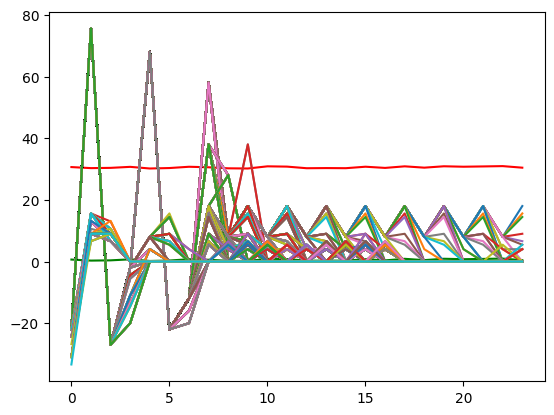

In [9]:
for r in array_consumption:
    r.reverse()


plt.plot(generated, color='green')
plt.plot(consump, color = 'red')

for a in array_consumption:
    plt.plot(a)

plt.savefig("images\\Search\\Flexibilidad\\DFS_Poda\\Flexibilidad_Consumo_{}.png".format(date.today()))

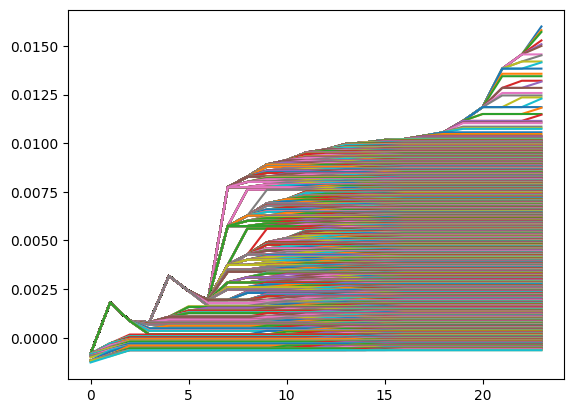

In [10]:
for r in array_price:
    r.reverse()
for a in array_price:
    plt.plot(a)
plt.savefig("images\\Search\\Flexibilidad\\DFS_Poda\\Flexibilidad_Precios_{}.png".format(date.today()))

In [11]:
estado = resultado_servicio_flexibilidad[0]
print(estado)

{
    "consumption": 18.0,
    "cumulative_consumption": 324.6,
    "price": 0.0014353200000000001,
    "cumulative_price": 0.015998661999999997,
    "_episode_ended": true,
    "day_step": 23,
    "actions": {
        "aire_zona_A": 5,
        "aire_zona_B": 5,
        "loxone_battery": 0
    },
    "agents_info": {
        "aire_zona_A": {
            "state": 4,
            "temperature": 21.125
        },
        "aire_zona_B": {
            "state": 4,
            "temperature": 21.5
        },
        "loxone_battery": {
            "soc": 52.936605,
            "chargeHistory": 160,
            "dischargeHistory": 160
        }
    },
    "specific": {}
}


In [12]:
actual = estado.father
while actual:
    print(actual)
    actual = actual.father

{
    "consumption": 8.0,
    "cumulative_consumption": 306.6,
    "price": 0.0007308,
    "cumulative_price": 0.014563341999999998,
    "_episode_ended": false,
    "day_step": 22,
    "actions": {
        "aire_zona_A": 3,
        "aire_zona_B": 3,
        "loxone_battery": 0
    },
    "agents_info": {
        "aire_zona_A": {
            "state": 2,
            "temperature": 23.125
        },
        "aire_zona_B": {
            "state": 2,
            "temperature": 23.5
        },
        "loxone_battery": {
            "soc": 52.936605,
            "chargeHistory": 160,
            "dischargeHistory": 160
        }
    },
    "specific": {}
}
{
    "consumption": 18.0,
    "cumulative_consumption": 298.6,
    "price": 0.0019782,
    "cumulative_price": 0.013832541999999998,
    "_episode_ended": false,
    "day_step": 21,
    "actions": {
        "aire_zona_A": 5,
        "aire_zona_B": 5,
        "loxone_battery": 0
    },
    "agents_info": {
        "aire_zona_A": {
        